Missing values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Dataset cleaned successfully!
Shape: (7043, 20)
gender                int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure                int64
PhoneService          int64
MultipleLines         int64
InternetService       int64
OnlineSecurity        int64
OnlineBackup          int64
DeviceProtection      int64
TechSupport           int64
StreamingTV           int64
StreamingMovies       int64
Contract              int64
PaperlessBilling      int64
PaymentMethod         int64
Monthl

<Axes: >

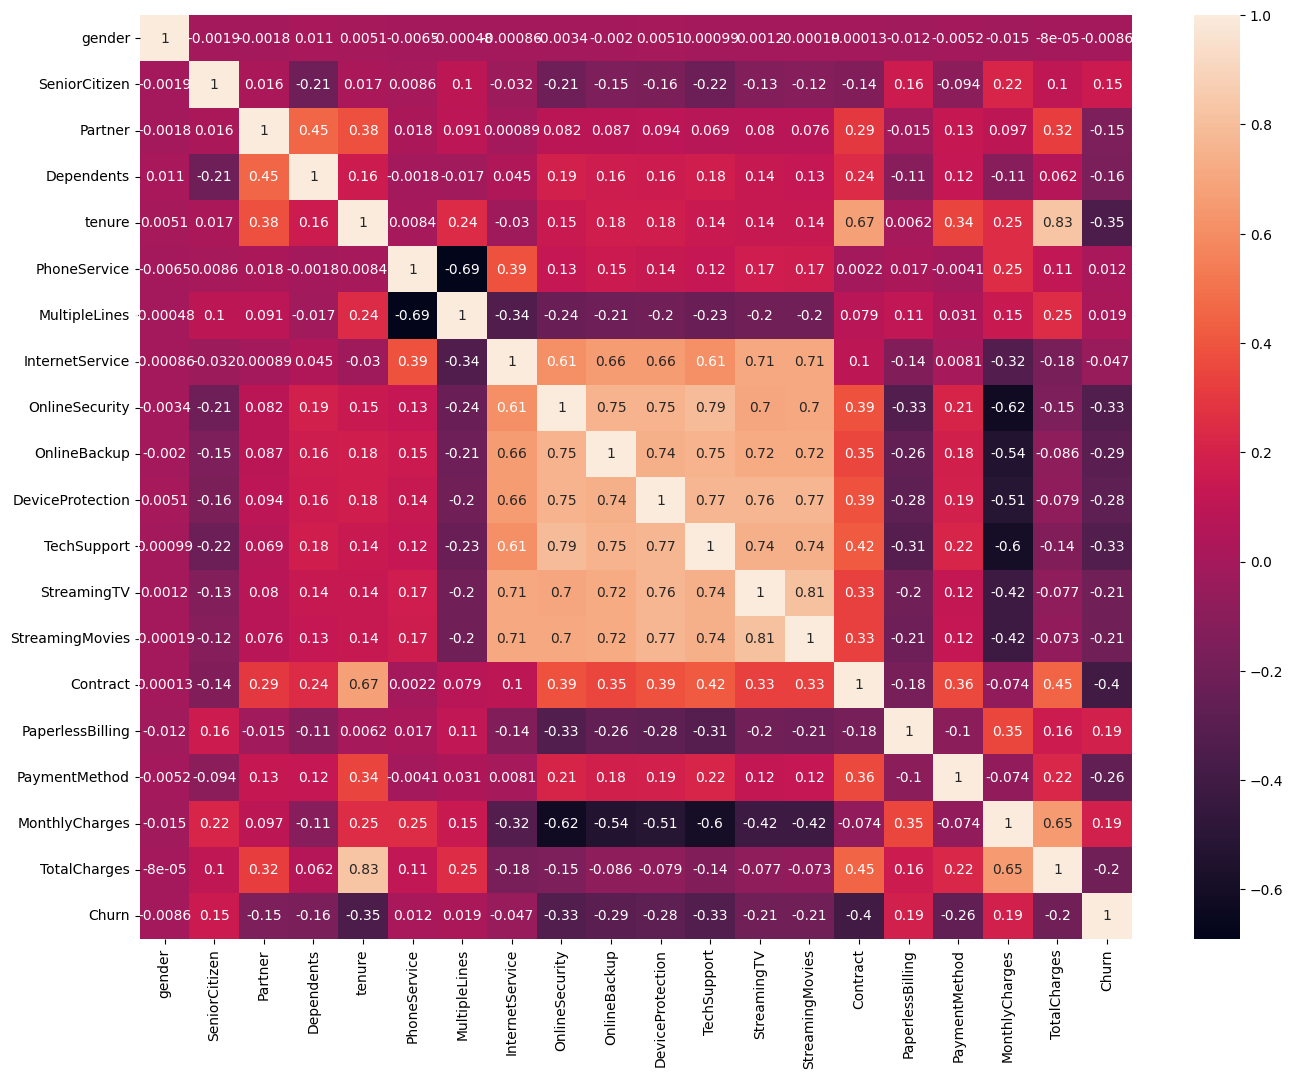

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

df = pd.read_csv("Telco-Customer-Churn.csv")

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df.drop(columns=["customerID"], inplace=True)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

binary_columns = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling",
    "Churn"
]

for col in binary_columns:
    if col == "gender":
        df[col] = df[col].map({
            "Female": 0,
            "Male": 1
        })
    else:
        df[col] = df[col].map({
            "No": 0,
            "Yes": 1
        })

mapping = {
    "MultipleLines": {
        "No": 0,
        "Yes": 1,
        "No phone service": 2
    },
    "InternetService": {
        "DSL": 0,
        "Fiber optic": 1,
        "No": 2
    },
    "OnlineSecurity": {
        "No": 0,
        "Yes": 1,
        "No internet service": 2
    },
    "OnlineBackup": {
        "No": 0,
        "Yes": 1,
        "No internet service": 2
    },
    "DeviceProtection": {
        "No": 0,
        "Yes": 1,
        "No internet service": 2
    },
    "TechSupport": {
        "No": 0,
        "Yes": 1,
        "No internet service": 2
    },
    "StreamingTV": {
        "No": 0,
        "Yes": 1,
        "No internet service": 2
    },
    "StreamingMovies": {
        "No": 0,
        "Yes": 1,
        "No internet service": 2
    },
    "Contract": {
        "Month-to-month": 0,
        "One year": 1,
        "Two year": 2
    },
    "PaymentMethod": {
        "Electronic check": 0,
        "Mailed check": 1,
        "Bank transfer (automatic)": 2,
        "Credit card (automatic)": 3
    }
}

for col, values in mapping.items():
    df[col] = df[col].map(values)


text_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

if text_columns:
    raise ValueError(
        f" a : {text_columns}"
    )


print("Missing values:")
print(df.isnull().sum())


df.to_csv(
    "Telco-Customer-Churn-Cleaned.csv",
    index=False
)


print("\nDataset cleaned successfully!")
print("Shape:", df.shape)
print(df.dtypes)
print(df.head())

plt.figure(figsize=(16,12))
sns.heatmap(df.corr(),annot=True)



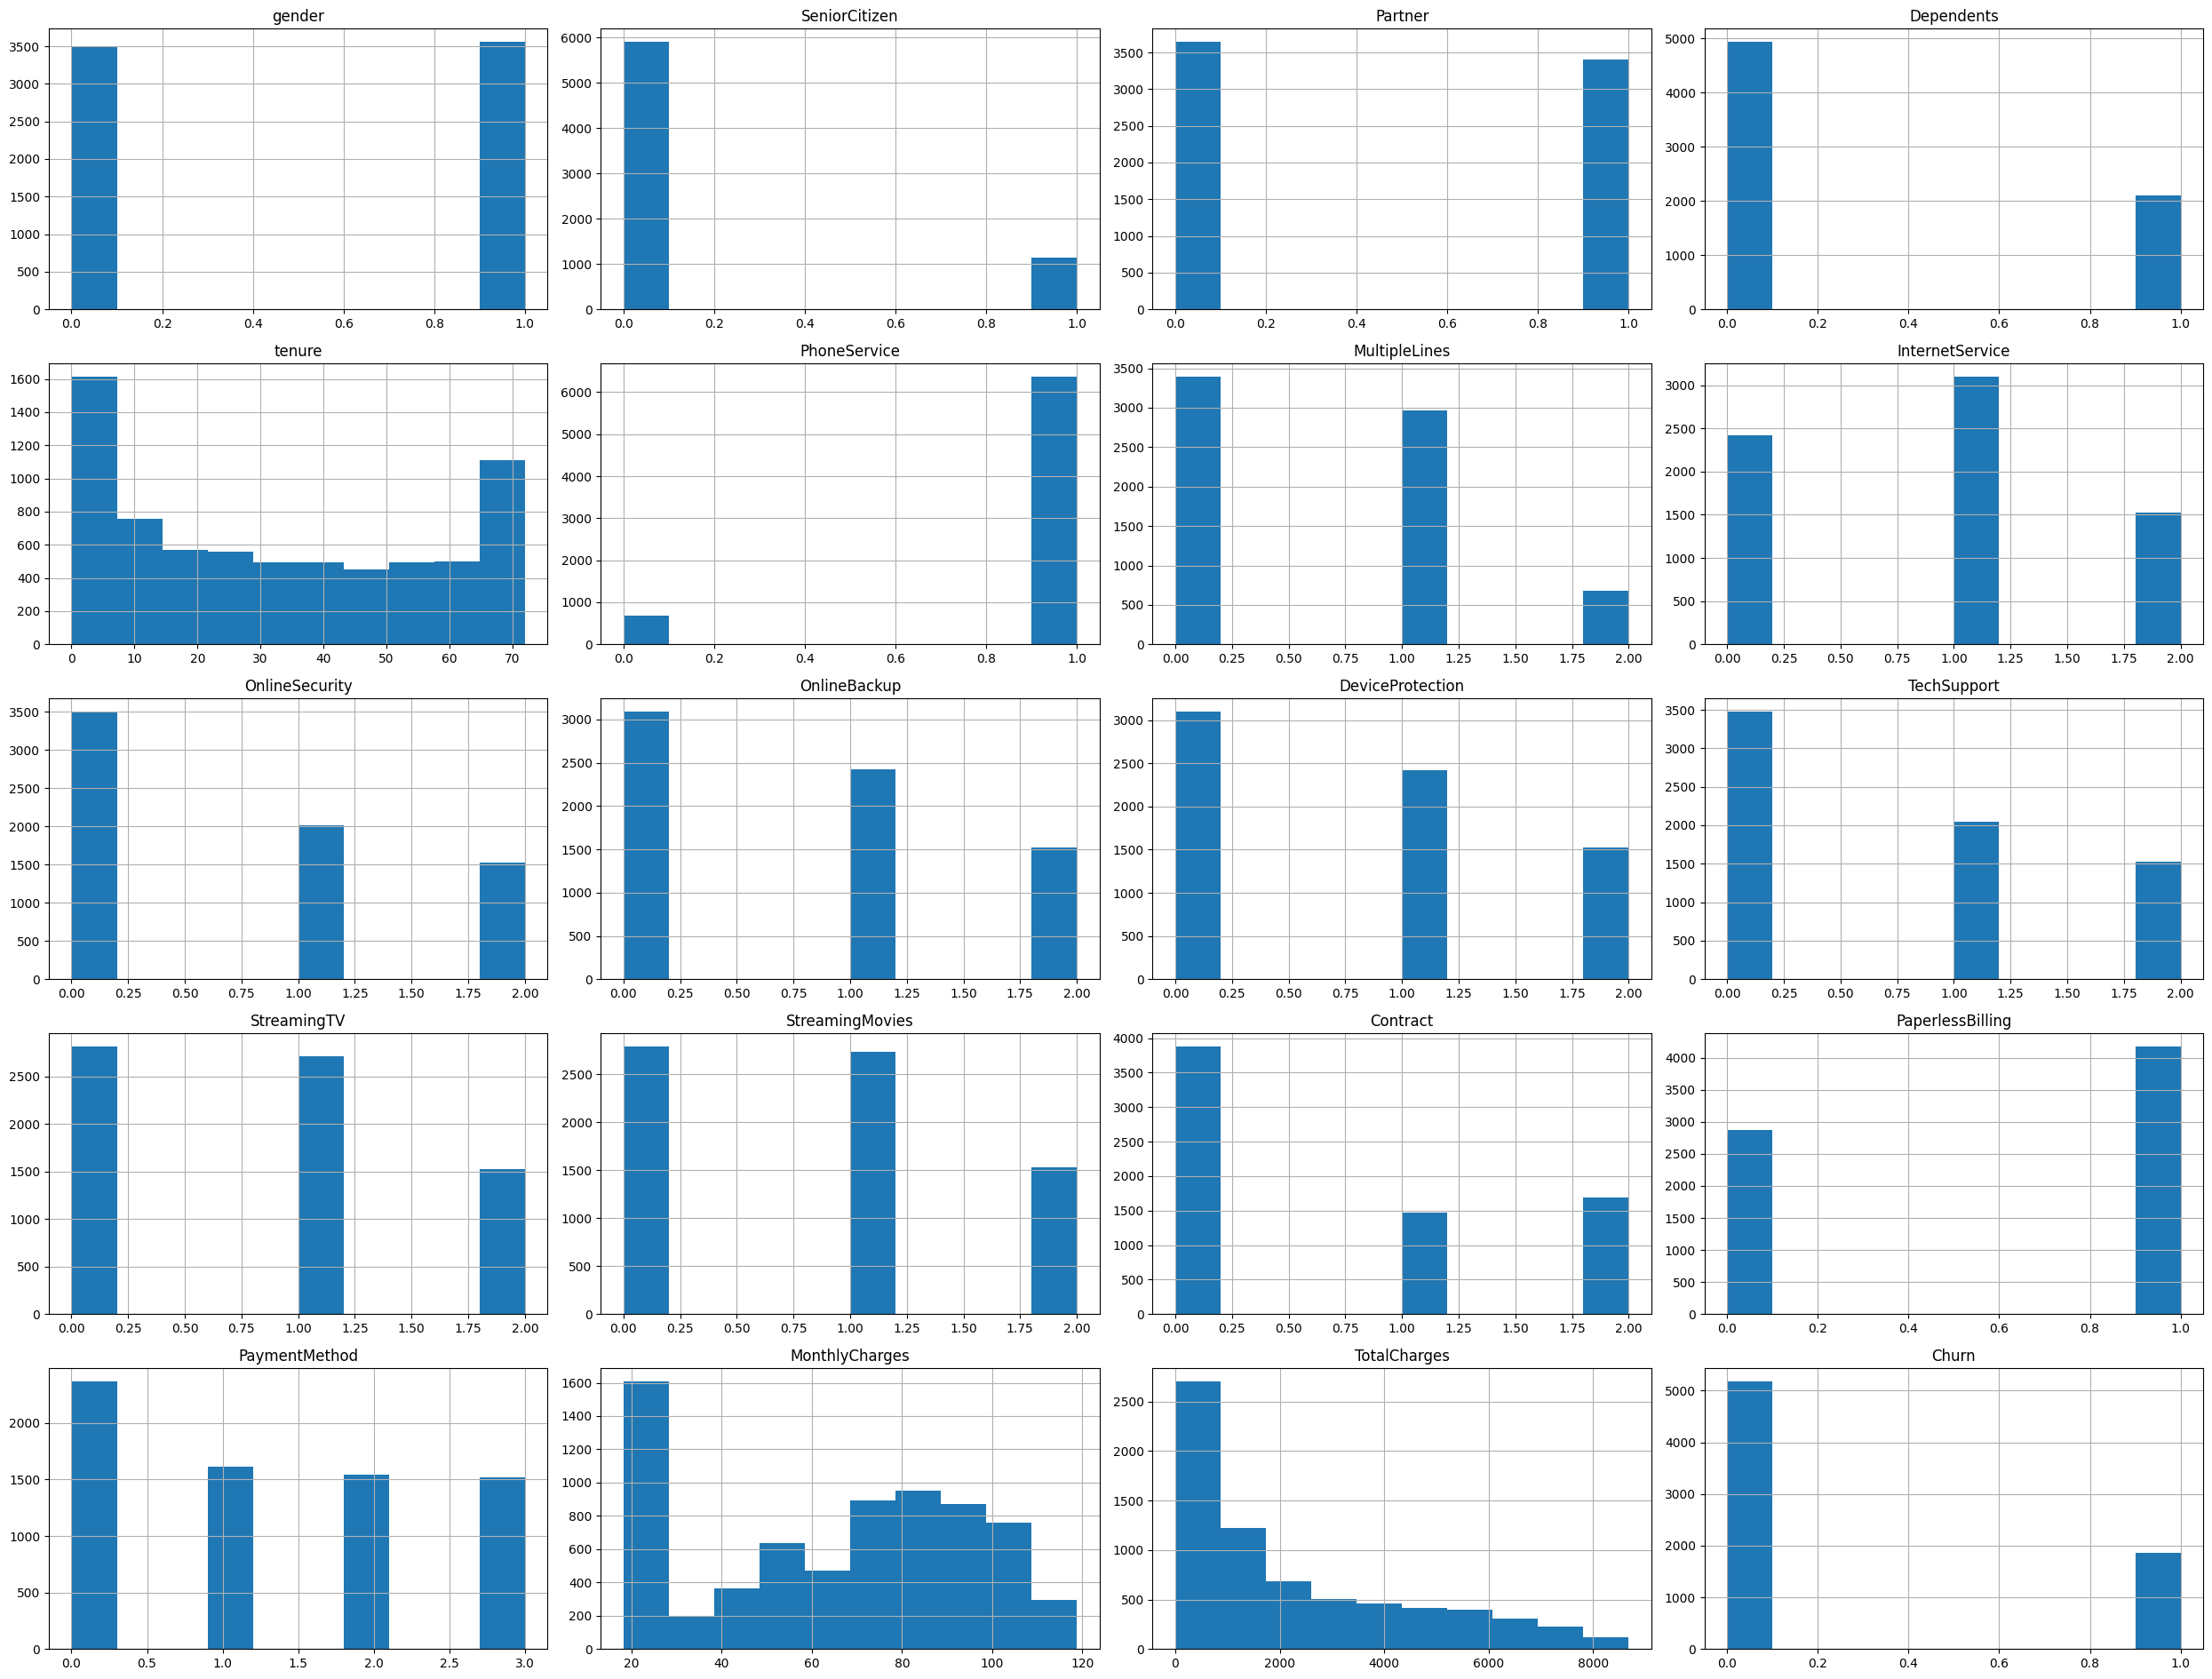

In [8]:
df.hist(figsize=(25,19))
plt.tight_layout()
plt.show()

<Axes: >

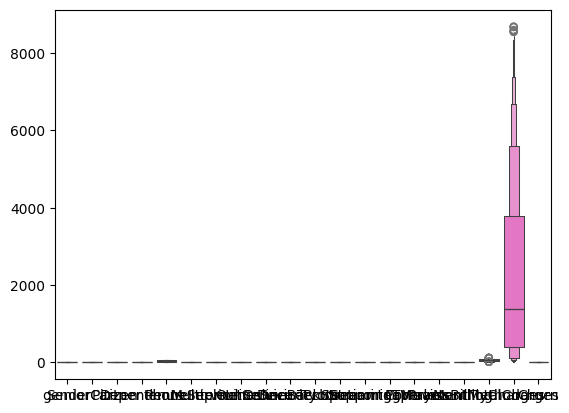

In [11]:
plt.Figure(figsize=(15,10))
sns.boxenplot(df)

In [12]:
x = df.drop("Churn",axis=1)
y = df["Churn"]
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [13]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)


In [15]:
from sklearn.metrics import accuracy_score

for name, model in {
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f'{name} Accuracy: {accuracy_score(y_test, y_pred):.4f}')


Random Forest Accuracy: 0.7956
XGBoost Accuracy: 0.7956
